### Getting Started with MAF - Creating and Chatting with our Agent (At Microsoft Foundry Level)

## Notebook workflow

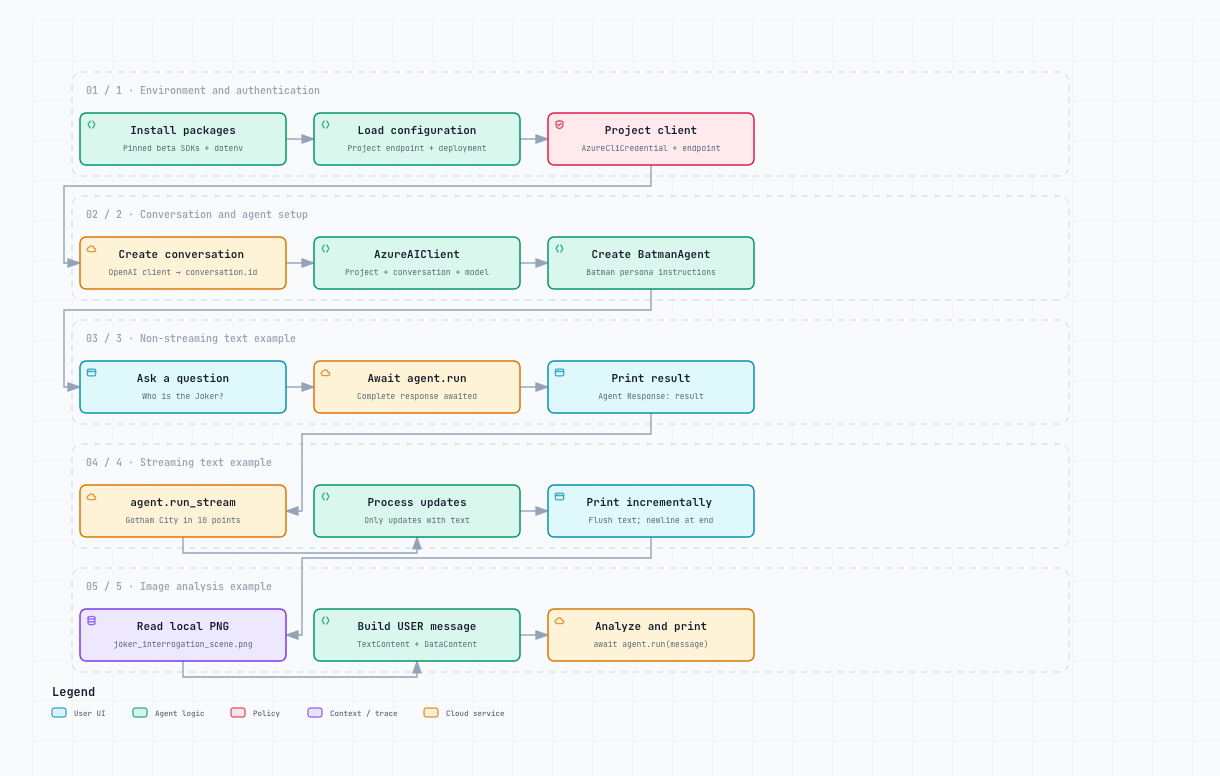

The examples reuse the same `BatmanAgent`, configured with a conversation ID and model deployment. Run setup first, then follow the three examples below.


![lab1](./Assets/lab1.png)

### Installing Required Libraries

In [1]:
# Install into the active notebook kernel; the version pins match this tutorial.
%pip install agent-framework==1.0.0b251209 python-dotenv azure-ai-projects==2.0.0b2

  Using cached agent_framework-1.0.0b251209-py3-none-any.whl.metadata (9.3 kB)
  Using cached azure_ai_projects-2.0.0b2-py3-none-any.whl.metadata (63 kB)
  Using cached agent_framework_core-1.0.0b251209-py3-none-any.whl.metadata (10 kB)
INFO: pip is looking at multiple versions of agent-framework-a2a to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of agent-framework-a2a to determine which version is compatible with other requirements. This could take a while.
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https://pip.pypa.io/warnings/backtracking for guidance. If you want to abort this run, press Ctrl + C.
INFO: pip is looking at multiple versions of agent-framework-ag-ui to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versio

### Setting Up the Environment

In [2]:
# os reads environment variables; dotenv loads local configuration from a .env file.
import os
from dotenv import load_dotenv
# This key-based credential is imported but unused; the agent below uses Azure CLI authentication.
from azure.core.credentials import AzureKeyCredential

# Load .env values without overriding environment variables that are already set.
load_dotenv()
# Read the Foundry project endpoint and the name of an existing model deployment.
project_endpoint = os.getenv("AI_FOUNDRY_PROJECT_ENDPOINT")
model = os.getenv("AI_FOUNDRY_DEPLOYMENT_NAME")

# Display the selected configuration to help confirm which project and deployment will be used.
print("Project Endpoint: ", project_endpoint)
print("Model: ", model)

Project Endpoint:  None
Model:  None


### Creating the Foundry Client and Agent

In [3]:
# AzureAIClient connects Agent Framework to the Foundry project client.
from agent_framework.azure import AzureAIClient
# The .aio imports provide asynchronous Azure authentication and project operations.
from azure.identity.aio import AzureCliCredential
from azure.ai.projects.aio import AIProjectClient

# Bundle setup in an async function so conversation creation can be awaited.
async def create_agent():
    # Authenticate using the Azure CLI account signed in with az login.
    credential = AzureCliCredential()
    
    # creating the Foundry Project Client
    # Combine the project endpoint with an identity used to authorize requests.
    project_client = AIProjectClient(
        endpoint=project_endpoint,
        credential=credential
    )

    # creating a conversation using the OpenAI Client
    # Obtain the project-scoped OpenAI client for conversation operations.
    openai_client = project_client.get_openai_client()
    # Create a conversation and wait for the service to return its identifier.
    conversation = await openai_client.conversations.create()
    # Pass this ID to the adapter so subsequent examples use the same conversation.
    conversation_id = conversation.id
    print("Conversation ID: ", conversation_id)
    
    # creating the Azure AI Client to interact with the Agent in Foundry
    # Bind project access, conversation context, and the chosen model deployment.
    agent_client = AzureAIClient(
        project_client = project_client,
        conversation_id = conversation_id,
        model_deployment_name=model
    )
    
    # creating an agent in Foundry
    # Create the agent object with its name and Batman persona instructions.
    agent = agent_client.create_agent(
        name="BatmanAgent",
        instructions="You are Batman, the dark knight of Gotham City."
    )
    # Return the agent for chat and retain references to its credential and adapter.
    return agent, credential, agent_client

# Top-level await runs setup in the notebook and exposes the returned objects to later cells.
agent, credential, agent_client = await create_agent()

ImportError: cannot import name 'AzureAIClient' from 'agent_framework.azure' (/Users/sanskarsrivastava/Desktop/Foundry/MicrosoftFoundry/.venv/lib/python3.13/site-packages/agent_framework/azure/__init__.py)

### Chatting with the Agent - Non Streaming

In [ ]:
# Reuse the agent created above for a request that returns a complete result.
async def non_streaming_example():
    # Prepare the user prompt as plain text.
    query = "Who is the Joker?"
    # Pause this coroutine until the agent run finishes; no partial updates are printed.
    result = await agent.run(query)
    # Print the returned result object.
    print("Agent Response:", result)

# Execute the example using the notebook event loop.
await non_streaming_example()

### Chatting with the Agent - Streaming

In [ ]:
# Running the agent with streaming responses
async def streaming_chat():
    # Consume response updates as they arrive instead of awaiting one complete result.
    async for update in agent.run_stream("Tell me something interesting about Gotham City in 10 points"):
        # Some updates contain no text; print only those with text content.
        if update.text:
            # Append text without added newlines and flush it immediately to the output.
            print(update.text, end="", flush=True)
    print()  # New line after streaming is complete

# Run the streaming example with the same agent and conversation configuration.
await streaming_chat()

### Giving our Agent an Image

![joker_interrogation](./Assets/joker_interrogation_scene.png)

In [ ]:
# These message types let one user message carry both a text prompt and image bytes.

# ChatMessage: the complete message envelope.
# TextContent: text inside the message.
# DataContent: binary data, such as an image.
# Role: identifies who sent the message.

from agent_framework import ChatMessage, TextContent, DataContent, Role

# Load image from local file
# Read relative to the kernel working directory; rb opens the PNG as binary data.
with open("./Assets/joker_interrogation_scene.png", "rb") as image_file:
    # Keep the image bytes in memory after the with block closes the file.
    image_bytes = image_file.read()

# Create a message with text and image data
message = ChatMessage(
    # Mark the message as user input rather than an assistant or system message.
    role = Role.USER,
    # Combine an instruction and the image it refers to in the same message.
    contents = [
        TextContent(text = "Tell me about the incident in this image."),
        # Supply the actual image bytes, with a media type identifying the PNG format.
        DataContent(
            data = image_bytes,
            media_type = "image/png"
        )
    ]
)

# Creating an async function for the entire image analysis run
async def analyze_image():
    # Send the multimodal message through the existing agent and await the complete response.
    response = await agent.run(message)
    # Display the text portion of the response.
    print(f"Agent: {response.text}")

# invoke the async function
# Run image analysis after the message and agent have been created.
await analyze_image()